# Combine Multiple BIM Models into a Single Feature Dataset
This sample shows how to combine multiple BIM models into a single feature dataset. For additional tips, see the workflow in the [Combine multiple digital models into a single building scene layer](https://www.esri.com/arcgis-blog/products/arcgis-pro/aec/combine-multiple-digital-models-into-a-single-building-scene-layer) blog article.

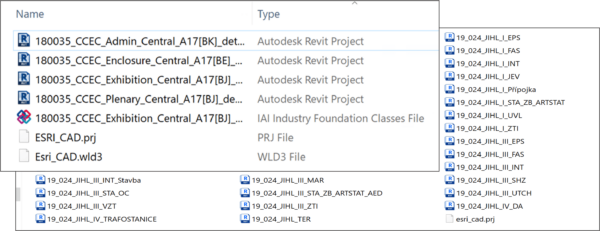

## Use case
A single project often contains more than one BIM model. For use in GIS, analysts often prefer a single feature dataset that combines the models and omits floorplan details. This sample shows how to use the **BIM File to Geodatabase** geoprocessing tool to combine all BIM models stored in a single folder. 

## Requirements
The following are required before using this notebook:
- You must have an existing geodatabase.
- Your BIM models should be georeferenced and in the same coordinate system. 

## Use the sample
Download the Jupyter notebook. Change the variable paths and values to fit your working environment and project.

### Prepare variables

In [ ]:
import arcpy
import os
arcpy.env.overwriteOutput = True

In [ ]:
# Folder that contains Revit and/or IFC files that will be converted to geodatabase feature classes.
bim_file_folder = r'C:\MyBIMFiles\Revit'

# The full path to an existing geodatabase where the output feature dataset will be created. 
gdb_path = r"C:\Projects\MyProjectName\MyProject\MyProject.gdb"

# Optionally, provide a spatial reference for the output feature dataset. 
# The default will use the spatial reference defined by the first model found.
optional_spatial_reference = "NAD_1983_2011_StatePlane_Maine_East_FIPS_1801_Ft_US"

# The output feature dataset name. 
dataset_name = "MyBIMDataset"

In [ ]:
def get_bim_files(folder_path, valid_formats = (".rvt", ".ifc")):
    """
    Traverse the folder and find BIM models (e.g., .rvt, .ifc).

    Args:
        folder_path (str): The folder to search.
        valid_formats (tuple): A tuple of supported file extensions.

    Returns:
        list: A list of full file paths of the BIM models.
    """
    bim_file_paths = []

    for root, dirs, filenames in os.walk(folder_path):
        for filename in filenames:
            if filename.lower().endswith(valid_formats):
                full_path = os.path.join(root, filename)
                bim_file_paths.append(full_path)
    return bim_file_paths

The list of files will be used as the **Input BIM File Workspace** parameter in the **BIM File To Geodatabase** geoprocessing tool.

In [ ]:
bim_file_paths = get_bim_files(bim_file_folder)

### Run the geoprocessing tool to combine the models

Use the list of files from `bim_file_paths` in the **Input BIM File Workspace**.

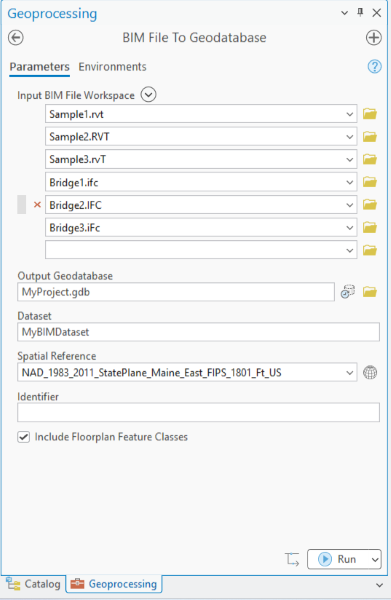


Note: Because the environment is set to overwrite the output, if `dataset_name` exists in the target geodatabase, it will be overwritten.

In [ ]:
arcpy.conversion.BIMFileToGeodatabase(
    in_bim_file_workspace = bim_file_paths,
    out_gdb_path = gdb_path,
    out_dataset_name = dataset_name,
    spatial_reference = optional_spatial_reference,
    include_floorplan = "EXCLUDE_FLOORPLAN"
)

This tool creates all feature classes in the output feature dataset, regardless of whether they have content. You may receive the warning message `WARNING 000117: Warning empty output generated`. 

### Next steps
You have many options for next steps. You can share the combined feature dataset as a hosted building scene layer, recategorize BIM features (see [this sample](../Recategorize%20BIM%20Features/RecategorizeBIMFeatures.ipynb)), enhance the exterior shell (see [this sample](../Improve%20Exterior%20Shell%20of%20Building%20Scene%20Layer/ImproveExteriorShell.ipynb)), or take other actions to suit your workflows. 